# NeurIPS BMMC - LIGER Default vs Best UMAP

Fixed seed: `1`. Left column: cell type. Right column: batch.
Default is the top row and Best is the bottom row. Each column uses one shared legend.

Selection deltas for this seed: bio `+0.080177`,
batch `+0.076414`, joint `+0.078671`.


In [1]:
import gc
import importlib.util
import os
import sys

os.environ["PYTHONNOUSERSITE"] = "1"
sys.path = [
    path
    for path in sys.path
    if ".local/lib/python3.10/site-packages" not in path
]

PROJECT_ROOT = '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics'
os.environ["R_HOME"] = f"{PROJECT_ROOT}/CondaEnv/pyliger_env/lib/R"
sys.path.insert(0, f"{PROJECT_ROOT}/scib/")

import anndata as ad
import numpy as np
import pandas as pd

OPTIMIZER_PATH = (
    f"{PROJECT_ROOT}/scripts/optuna_multi_metrics/"
    "optuna_liger/optimize_liger_multi_metrics.py"
)
optimizer_spec = importlib.util.spec_from_file_location(
    "liger_opt",
    OPTIMIZER_PATH,
)
if optimizer_spec is None or optimizer_spec.loader is None:
    raise ImportError(f"Cannot load LIGER optimizer: {OPTIMIZER_PATH}")
liger_opt = importlib.util.module_from_spec(optimizer_spec)
sys.modules[optimizer_spec.name] = liger_opt
optimizer_spec.loader.exec_module(liger_opt)


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATASET_NAME = 'neurips_bmmc'
DATA_PATH = f"{PROJECT_ROOT}/data/{DATASET_NAME}.h5ad"
BATCH_KEY = 'batch'
LABEL_KEY = 'cell_type'

SELECTED_BIO_METRICS = ('BAMI', 'CASW', 'SCGRAPHM', 'TRAJ', 'ISOLISI')
SELECTED_BATCH_METRICS = ('BRAS', 'KBET', 'CPCR')
SELECTED_METRICS = SELECTED_BIO_METRICS + SELECTED_BATCH_METRICS

SEEDS = tuple(range(1, 11))
MODE = "core"
LAYER = "counts"
N_NEIGHBORS = 15
EMBED_KEY = "X_liger"

liger_opt.DATASET_NAME = DATASET_NAME
liger_opt.DATA_PATH = DATA_PATH
liger_opt.BATCH_KEY = BATCH_KEY
liger_opt.LABEL_KEY = LABEL_KEY
liger_opt.MODE = MODE
liger_opt.LAYER = LAYER
liger_opt.USE_BAMI = "BAMI" in SELECTED_METRICS
liger_opt.USE_CASW = "CASW" in SELECTED_METRICS
liger_opt.USE_SCGRAPHM = "SCGRAPHM" in SELECTED_METRICS
liger_opt.USE_TRAJ = "TRAJ" in SELECTED_METRICS
liger_opt.USE_ISOLISI = "ISOLISI" in SELECTED_METRICS
liger_opt.USE_BRAS = "BRAS" in SELECTED_METRICS
liger_opt.USE_KBET = "KBET" in SELECTED_METRICS
liger_opt.USE_CPCR = "CPCR" in SELECTED_METRICS

assert DATASET_NAME == 'neurips_bmmc'
assert BATCH_KEY == 'batch'
assert LABEL_KEY == 'cell_type'
assert SELECTED_METRICS == ('BAMI', 'CASW', 'SCGRAPHM', 'TRAJ', 'ISOLISI', 'BRAS', 'KBET', 'CPCR')
assert SEEDS == tuple(range(1, 11))
assert liger_opt.CORE_MAX_ITERS == 30
assert liger_opt.N_NEIGHBORS == N_NEIGHBORS
assert liger_opt.EMBED_KEY == EMBED_KEY

pd.Series(
    {
        "dataset": DATASET_NAME,
        "data_path": DATA_PATH,
        "batch_key": BATCH_KEY,
        "label_key": LABEL_KEY,
        "metrics": list(SELECTED_METRICS),
        "seeds": list(SEEDS),
        "mode": MODE,
        "layer": LAYER,
    },
    name="configuration",
)


dataset                                           neurips_bmmc
data_path    /ubc/cs/research/beaver/projects/Single-cell-i...
batch_key                                                batch
label_key                                            cell_type
metrics      [BAMI, CASW, SCGRAPHM, TRAJ, ISOLISI, BRAS, KB...
seeds                          [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
mode                                                      core
layer                                                   counts
Name: configuration, dtype: object

In [3]:
from pathlib import Path
import anndata as ad
import matplotlib.pyplot as plt
import scanpy as sc
from IPython.display import Image, display
from matplotlib.lines import Line2D

METHOD_NAME = 'LIGER'
DATASET_DISPLAY = 'NeurIPS BMMC'
SEED = 1
UMAP_ROOT = Path(
    PROJECT_ROOT,
    "notebooks",
    "optuna_multimetrics_tests",
    "UMAP",
)
FIGURE_ROOT = UMAP_ROOT / "figures"
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_STEM = 'bmmc_liger_seed1_default_vs_best_umap'
PNG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.png"
SVG_PATH = FIGURE_ROOT / f"{FIGURE_STEM}.svg"

assert DATASET_NAME == 'neurips_bmmc'
assert SEED == 1

pd.Series(
    {
        "dataset": DATASET_NAME,
        "method": METHOD_NAME,
        "seed": SEED,
        "cell_type_key": LABEL_KEY,
        "batch_key": BATCH_KEY,
        "embedding_key": EMBED_KEY,
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
    },
    name="umap_configuration",
)


dataset                                               neurips_bmmc
method                                                       LIGER
seed                                                             1
cell_type_key                                            cell_type
batch_key                                                    batch
embedding_key                                              X_liger
png              /ubc/cs/research/beaver/projects/Single-cell-i...
svg              /ubc/cs/research/beaver/projects/Single-cell-i...
Name: umap_configuration, dtype: object

In [4]:
liger_opt.validate_metric_dependencies()
liger_opt.validate_configuration(list(SELECTED_METRICS))
liger_opt.validate_dataset_contents()


Dataset preflight: n_obs=90261 n_batches=12 n_labels=45
TRAJ preflight: usable_pseudotime=51407 unique_values=51251
ISOLISI preflight: min_batch_coverage=1 isolated_labels=['CD8+ T naive CD127+ CD26- CD101-', 'T prog cycling', 'cDC1']
CPCR preflight: eligible_labels=40


In [5]:
LIGER_DEFAULT_ARGS = {
    "k": 20,
    "value_lambda": 5.0,
    "max_iters": 30,
    "mode": "core",
    "layer": "counts",
}


def run_liger_default(adata, seed):
    return liger_opt.run_liger(
        adata=adata,
        k=LIGER_DEFAULT_ARGS["k"],
        lam=LIGER_DEFAULT_ARGS["value_lambda"],
        max_iterations=LIGER_DEFAULT_ARGS["max_iters"],
        mode=LIGER_DEFAULT_ARGS["mode"],
        layer=LIGER_DEFAULT_ARGS["layer"],
        seed=seed,
    )


pd.Series(LIGER_DEFAULT_ARGS, name="default_setting")


k                   20
value_lambda       5.0
max_iters           30
mode              core
layer           counts
Name: default_setting, dtype: object

In [6]:
print(f"Running Default with seed {SEED}", flush=True)
adata_default = run_liger_default(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_default.obsm
assert adata_default.obsm[EMBED_KEY].shape[0] == adata_default.n_obs
assert np.isfinite(adata_default.obsm[EMBED_KEY]).all()
adata_default


Running Default with seed 1


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:344: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:344: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the calling code (compiling a ufunc more than once for the same signature
/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/dufunc.py:344: NumbaWarning: Compilation requested for previously compiled argument types ((uint32,)). This has no effect and perhaps indicates a bug in the

Removing 228 genes not expressing in s2d5.
Removing 821 genes not expressing in s3d1.


Removing 47 genes not expressing in s4d1.
Removing 162 genes not expressing in s4d8.


Removing 73 genes not expressing in s4d9.


...

 97%|█████████▋| 29/30 [12:56<00:26, 26.77s/it]

100%|██████████| 30/30 [13:22<00:00, 26.78s/it]

100%|██████████| 30/30 [13:22<00:00, 26.76s/it]

[LIGER PARAMS] function=quantile_norm rand_seed=1


AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'dpt_pseudotime', 'coarse_cell_type', 'broad_cell_type'
    var: 'feature_types', 'gene_id', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'batch_colors', 'broad_cell_type_colors', 'cell_type_colors', 'coarse_cell_type_colors', 'dataset_id', 'genome', 'hvg', 'log1p', 'neighbors', 'organism', 'pca', 'species', 'umap'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap', 'X_pca', 'X_umap', 'X_liger'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'dista

In [7]:
OPTUNA_STUDY_NAME = 'liger_neurips_bmmc_joint_expanded_metrics_scgraphm_v1'
OPTUNA_BEST_TRIAL = 68
OPTUNA_BEST_VALUE = 0.7252119817841958
OPTUNA_BEST_PARAMS = {'k': 54, 'value_lambda': 6.047214048759388}

LIGER_BEST_ARGS = {
    "k": OPTUNA_BEST_PARAMS["k"],
    "value_lambda": OPTUNA_BEST_PARAMS["value_lambda"],
    "max_iters": 30,
    "mode": "core",
    "layer": "counts",
}


def run_liger_best(adata, seed):
    return liger_opt.run_liger(
        adata=adata,
        k=LIGER_BEST_ARGS["k"],
        lam=LIGER_BEST_ARGS["value_lambda"],
        max_iterations=LIGER_BEST_ARGS["max_iters"],
        mode=LIGER_BEST_ARGS["mode"],
        layer=LIGER_BEST_ARGS["layer"],
        seed=seed,
    )


pd.Series(
    {
        "study": OPTUNA_STUDY_NAME,
        "best_trial": OPTUNA_BEST_TRIAL,
        "best_value": OPTUNA_BEST_VALUE,
        **LIGER_BEST_ARGS,
    },
    name="best_setting",
)


study           liger_neurips_bmmc_joint_expanded_metrics_scgr...
best_trial                                                     68
best_value                                               0.725212
k                                                              54
value_lambda                                             6.047214
max_iters                                                      30
mode                                                         core
layer                                                      counts
Name: best_setting, dtype: object

In [8]:
print(f"Running Best with seed {SEED}", flush=True)
adata_best = run_liger_best(
    ad.read_h5ad(DATA_PATH),
    seed=SEED,
)
assert EMBED_KEY in adata_best.obsm
assert adata_best.obsm[EMBED_KEY].shape[0] == adata_best.n_obs
assert np.isfinite(adata_best.obsm[EMBED_KEY]).all()
adata_best


Running Best with seed 1


Removing 228 genes not expressing in s2d5.
Removing 821 genes not expressing in s3d1.


Removing 47 genes not expressing in s4d1.
Removing 162 genes not expressing in s4d8.
Removing 73 genes not expressing in s4d9.


[LIGER PARAMS] function=optimize_ALS k=54 value_lambda=6.047214048759388 max_iters=30 rand_seed=1


  0%|          | 0/30 [00:00<?, ?it/s]

...

 97%|█████████▋| 29/30 [18:58<00:39, 39.02s/it]

100%|██████████| 30/30 [19:37<00:00, 39.04s/it]

100%|██████████| 30/30 [19:37<00:00, 39.24s/it]

[LIGER PARAMS] function=quantile_norm rand_seed=1


AnnData object with n_obs × n_vars = 90261 × 13953
    obs: 'GEX_n_genes_by_counts', 'GEX_pct_counts_mt', 'GEX_size_factors', 'GEX_phase', 'ADT_n_antibodies_by_counts', 'ADT_total_counts', 'ADT_iso_count', 'cell_type', 'batch', 'ADT_pseudotime_order', 'GEX_pseudotime_order', 'Samplename', 'Site', 'DonorNumber', 'Modality', 'VendorLot', 'DonorID', 'DonorAge', 'DonorBMI', 'DonorBloodType', 'DonorRace', 'Ethnicity', 'DonorGender', 'QCMeds', 'DonorSmoker', 'is_train', 'dpt_pseudotime', 'coarse_cell_type', 'broad_cell_type'
    var: 'feature_types', 'gene_id', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'batch_colors', 'broad_cell_type_colors', 'cell_type_colors', 'coarse_cell_type_colors', 'dataset_id', 'genome', 'hvg', 'log1p', 'neighbors', 'organism', 'pca', 'species', 'umap'
    obsm: 'ADT_X_pca', 'ADT_X_umap', 'ADT_isotype_controls', 'GEX_X_pca', 'GEX_X_umap', 'X_pca', 'X_umap', 'X_liger'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'dista

In [9]:
assert adata_default.obs_names.equals(adata_best.obs_names)
assert LABEL_KEY in adata_default.obs
assert BATCH_KEY in adata_default.obs
assert adata_default.obs[LABEL_KEY].equals(adata_best.obs[LABEL_KEY])
assert adata_default.obs[BATCH_KEY].equals(adata_best.obs[BATCH_KEY])

for setting_name, adata_setting in (
    ("Default", adata_default),
    ("Best", adata_best),
):
    sc.pp.neighbors(
        adata_setting,
        n_neighbors=N_NEIGHBORS,
        use_rep=EMBED_KEY,
        random_state=SEED,
    )
    sc.tl.umap(adata_setting, random_state=SEED)
    assert "X_umap" in adata_setting.obsm
    assert np.isfinite(adata_setting.obsm["X_umap"]).all()
    print(
        setting_name,
        adata_setting.obsm["X_umap"].shape,
        flush=True,
    )


/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/CondaEnv/pyliger_env/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.


Default (90261, 2)


Best (90261, 2)


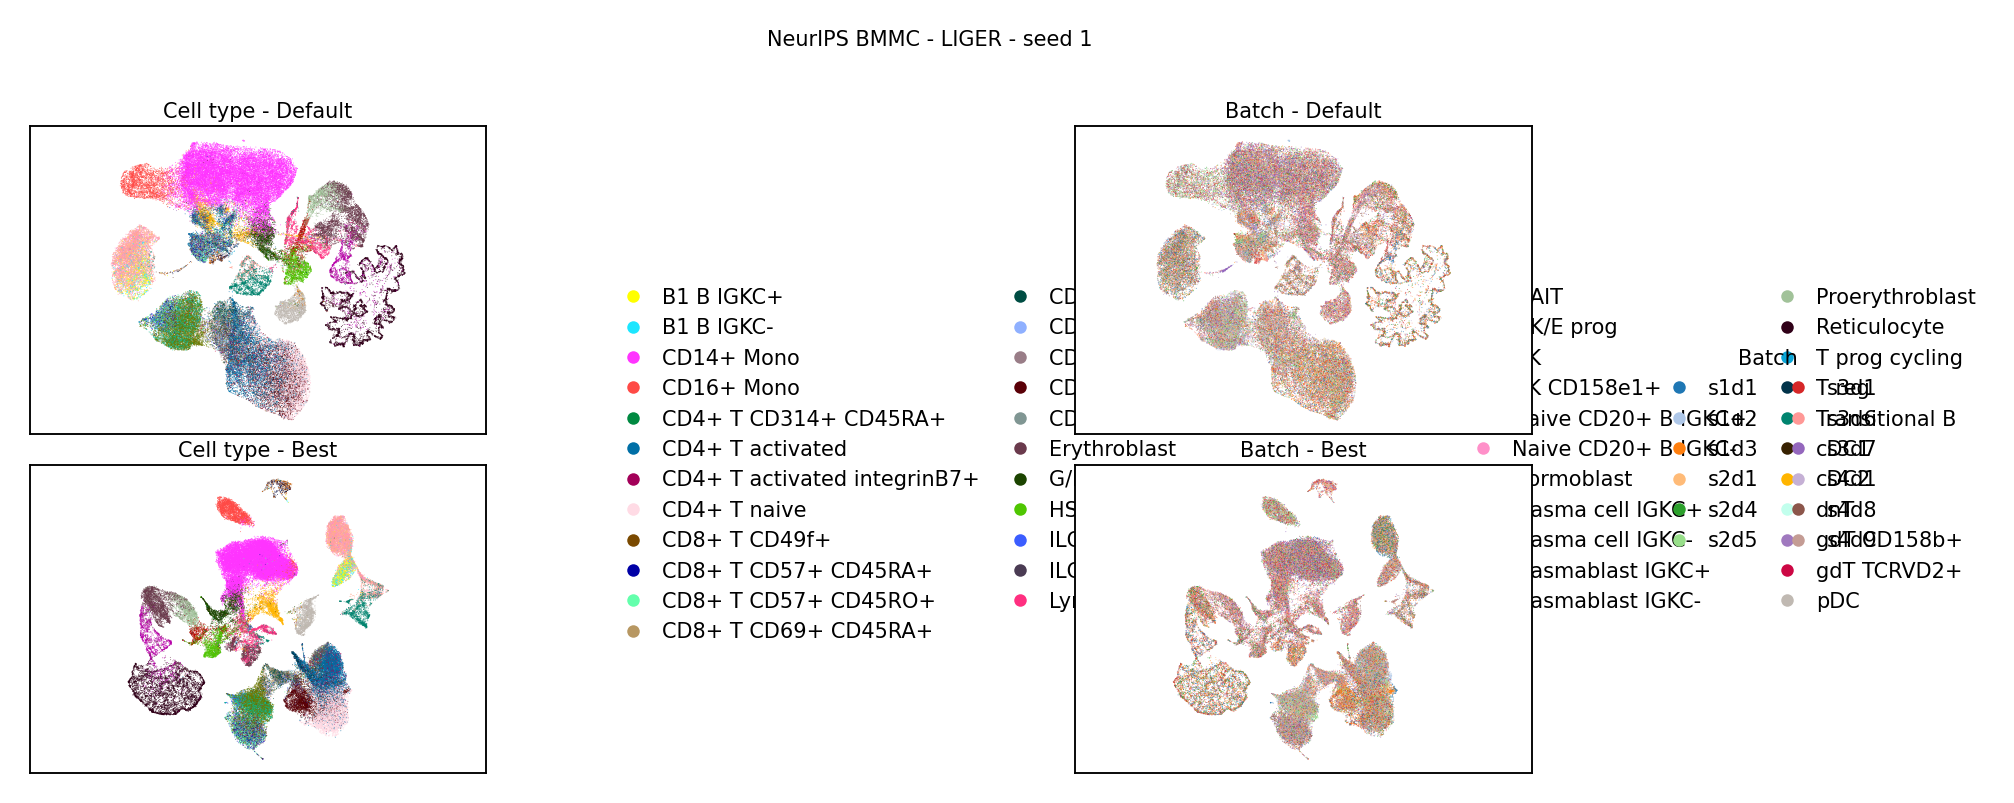

png           /ubc/cs/research/beaver/projects/Single-cell-i...
svg           /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                   90261
cell_types                                                   45
batches                                                      12
point_size                                                 0.05
Name: saved_figure, dtype: object

In [10]:
UMAP_SOURCE_TEXT_SIZE_PT = 5.0
UMAP_RASTER_DPI = 600


def ordered_categories(adata, key):
    values = adata.obs[key].astype(str)
    return tuple(sorted(pd.unique(values), key=str))


def category_palette(categories):
    if len(categories) <= len(sc.pl.palettes.default_102):
        colors = sc.pl.palettes.default_102[: len(categories)]
    else:
        cmap = plt.get_cmap("hsv", len(categories))
        colors = [cmap(index) for index in range(len(categories))]
    return dict(zip(categories, colors))


def scatter_panel(ax, adata, key, palette, title, order, point_size):
    values = adata.obs[key].astype(str).to_numpy()
    coordinates = adata.obsm["X_umap"]
    colors = [palette[value] for value in values[order]]
    ax.scatter(
        coordinates[order, 0],
        coordinates[order, 1],
        c=colors,
        s=point_size,
        alpha=0.78,
        linewidths=0,
        rasterized=False,
    )
    ax.set_title(
        title,
        fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
        pad=2,
    )
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.45)


def legend_handles(categories, palette):
    return [
        Line2D(
            [0],
            [0],
            marker="o",
            color="none",
            markerfacecolor=palette[category],
            markeredgecolor="none",
            markersize=3,
            label=category,
        )
        for category in categories
    ]


cell_categories = ordered_categories(adata_default, LABEL_KEY)
batch_categories = ordered_categories(adata_default, BATCH_KEY)
cell_palette = category_palette(cell_categories)
assert len(cell_categories) == 45
assert len(batch_categories) == 12
tab20_batch_colors = plt.get_cmap("tab20").colors
batch_palette = dict(
    zip(batch_categories, tab20_batch_colors[: len(batch_categories)])
)

cell_legend_columns = 4
batch_legend_columns = 2
max_legend_rows = max(
    int(np.ceil(len(cell_categories) / cell_legend_columns)),
    int(np.ceil(len(batch_categories) / batch_legend_columns)),
)
figure_height = max(2.8, 0.18 * max_legend_rows)
figure = plt.figure(figsize=(8.0, figure_height), dpi=250)
grid = figure.add_gridspec(
    2,
    4,
    width_ratios=(1.0, 0.82, 1.0, 0.55),
    hspace=0.10,
    wspace=0.28,
)
cell_default_axis = figure.add_subplot(grid[0, 0])
cell_best_axis = figure.add_subplot(grid[1, 0])
cell_legend_axis = figure.add_subplot(grid[:, 1])
batch_default_axis = figure.add_subplot(grid[0, 2])
batch_best_axis = figure.add_subplot(grid[1, 2])
batch_legend_axis = figure.add_subplot(grid[:, 3])

plot_order = np.random.default_rng(SEED).permutation(
    adata_default.n_obs
)
if adata_default.n_obs <= 20_000:
    point_size = 0.10
elif adata_default.n_obs <= 40_000:
    point_size = 0.07
elif adata_default.n_obs <= 100_000:
    point_size = 0.05
else:
    point_size = 0.03

scatter_panel(
    cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    cell_best_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Best",
    plot_order,
    point_size,
)
scatter_panel(
    batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    batch_best_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Best",
    plot_order,
    point_size,
)

cell_legend_axis.axis("off")
cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=cell_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)
batch_legend_axis.axis("off")
batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.9,
    handletextpad=0.4,
)

figure.suptitle(
    f"{DATASET_DISPLAY} - {METHOD_NAME} - seed {SEED}",
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    y=0.995,
)
figure.savefig(
    PNG_PATH,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)
figure.savefig(
    SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    bbox_inches="tight",
    facecolor="white",
)
plt.close(figure)

display(Image(filename=str(PNG_PATH)))
pd.Series(
    {
        "png": str(PNG_PATH),
        "svg": str(SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
    },
    name="saved_figure",
)


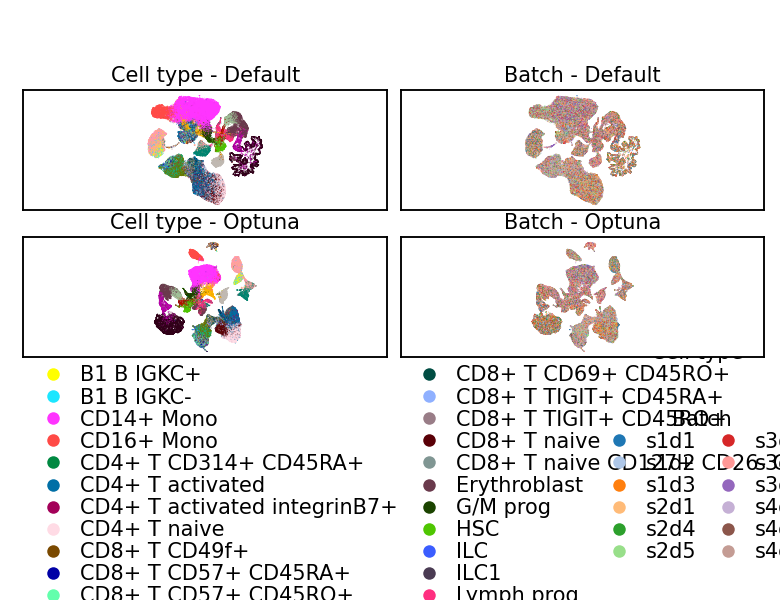

png            /ubc/cs/research/beaver/projects/Single-cell-i...
svg            /ubc/cs/research/beaver/projects/Single-cell-i...
n_cells                                                    90261
cell_types                                                    45
batches                                                       12
point_size                                                  0.05
panel_label                                               Optuna
suptitle                                                   False
Name: saved_revised_figure, dtype: object

In [11]:
revised_figure = plt.figure(
    figsize=(6.5 / 2.5, 2.0),
    dpi=250,
)
revised_grid = revised_figure.add_gridspec(
    3,
    4,
    height_ratios=(1.0, 1.0, 1.7),
    width_ratios=(1.0, 1.0, 1.0, 1.0),
    hspace=0.18,
    wspace=0.08,
)
revised_cell_default_axis = revised_figure.add_subplot(revised_grid[0, 0:2])
revised_cell_optuna_axis = revised_figure.add_subplot(revised_grid[1, 0:2])
revised_cell_legend_axis = revised_figure.add_subplot(revised_grid[2, 0:3])
revised_batch_default_axis = revised_figure.add_subplot(revised_grid[0, 2:4])
revised_batch_optuna_axis = revised_figure.add_subplot(revised_grid[1, 2:4])
revised_batch_legend_axis = revised_figure.add_subplot(revised_grid[2, 3])

scatter_panel(
    revised_cell_default_axis,
    adata_default,
    LABEL_KEY,
    cell_palette,
    "Cell type - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_cell_optuna_axis,
    adata_best,
    LABEL_KEY,
    cell_palette,
    "Cell type - Optuna",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_default_axis,
    adata_default,
    BATCH_KEY,
    batch_palette,
    "Batch - Default",
    plot_order,
    point_size,
)
scatter_panel(
    revised_batch_optuna_axis,
    adata_best,
    BATCH_KEY,
    batch_palette,
    "Batch - Optuna",
    plot_order,
    point_size,
)

revised_cell_legend_axis.axis("off")
revised_cell_legend_axis.legend(
    handles=legend_handles(cell_categories, cell_palette),
    title="Cell type",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=cell_legend_columns,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)
revised_batch_legend_axis.axis("off")
revised_batch_legend_axis.legend(
    handles=legend_handles(batch_categories, batch_palette),
    title="Batch",
    loc="center left",
    frameon=False,
    fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    title_fontsize=UMAP_SOURCE_TEXT_SIZE_PT,
    ncol=batch_legend_columns,
    columnspacing=0.5,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0,
)

REVISED_FIGURE_STEM = f"{FIGURE_STEM}_optuna_no_suptitle"
REVISED_PNG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.png"
REVISED_SVG_PATH = FIGURE_ROOT / f"{REVISED_FIGURE_STEM}.svg"

revised_figure.subplots_adjust(
    left=0.03,
    right=0.98,
    bottom=0.02,
    top=0.85,
)
revised_figure.savefig(
    REVISED_PNG_PATH,
    dpi=300,
    facecolor="white",
)
revised_figure.savefig(
    REVISED_SVG_PATH,
    format="svg",
    dpi=UMAP_RASTER_DPI,
    facecolor="white",
)
plt.close(revised_figure)

display(Image(filename=str(REVISED_PNG_PATH)))
pd.Series(
    {
        "png": str(REVISED_PNG_PATH),
        "svg": str(REVISED_SVG_PATH),
        "n_cells": adata_default.n_obs,
        "cell_types": len(cell_categories),
        "batches": len(batch_categories),
        "point_size": point_size,
        "panel_label": "Optuna",
        "suptitle": False,
    },
    name="saved_revised_figure",
)
